<a href="https://colab.research.google.com/github/Dharshanthisside/ITA0616---Machine-learning/blob/main/Exp_20_Future_Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             mean_squared_error, r2_score, mean_absolute_error)

R2: 0.10892999185000674  MAE: 11.244388665200992
       Month  Predicted Sales
0   Jan 2025            431.3
1   Feb 2025            449.8
2   Mar 2025            464.7
3   Apr 2025            472.9
4   May 2025            473.3
5   Jun 2025            466.8
6   Jul 2025            456.2
7   Aug 2025            445.4
8   Sep 2025            438.3
9   Oct 2025            437.8
10  Nov 2025            445.2
11  Dec 2025            459.4


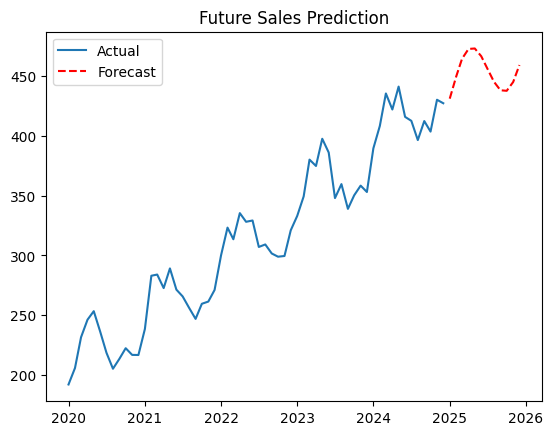

In [4]:
from sklearn.linear_model import LinearRegression

# 60 months of sales with trend + yearly seasonality
rng = np.random.default_rng(5)
months = pd.date_range('2020-01-01', periods=60, freq='MS')
t = np.arange(60)
sales = 200 + 4 * t + 30 * np.sin(2 * np.pi * t / 12) + rng.normal(0, 10, 60)
df = pd.DataFrame({'Date': months, 'Sales': sales})

def make_features(month, t):
    month = np.asarray(month)
    return pd.DataFrame({
        't': t,
        'sin': np.sin(2 * np.pi * month / 12),
        'cos': np.cos(2 * np.pi * month / 12),
    })

X = make_features(df['Date'].dt.month, t)
y = df['Sales']
X_train, X_test = X.iloc[:48], X.iloc[48:]
y_train, y_test = y.iloc[:48], y.iloc[48:]

model = LinearRegression().fit(X_train, y_train)
p = model.predict(X_test)
print("R2:", r2_score(y_test, p), " MAE:", mean_absolute_error(y_test, p))

# Forecast next 12 months
future_dates = pd.date_range('2025-01-01', periods=12, freq='MS')
future_t = np.arange(60, 72)
forecast = model.predict(make_features(future_dates.month, future_t))
print(pd.DataFrame({'Month': future_dates.strftime('%b %Y'), 'Predicted Sales': forecast.round(1)}))

plt.plot(df['Date'], df['Sales'], label='Actual')
plt.plot(future_dates, forecast, 'r--', label='Forecast')
plt.legend(); plt.title('Future Sales Prediction'); plt.show()